# Ablation of k-nearest neighbors in clustering

Effects of changing the $k$ in $k$-nearest neighbor graph construction performed prior to Louvain clustering.

In [1]:
import os
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import math
import colorcet as cc
from scipy.stats import wilcoxon, ttest_rel
from statsmodels.stats.multitest import multipletests

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

In [2]:
import rpy2.robjects as robjects
from rpy2.robjects import conversion, default_converter
from rpy2.robjects.pandas2ri import converter as pandas_converter

In [3]:
def compute_w_across_integrations(df):
    rank_df = df.copy()
    rank_df['Rank'] = rank_df.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='average')
    
    results = []
    for metric, group in rank_df.groupby('Metric'):
        pivot = group.pivot_table(index='Integration', columns='neighbor_k', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)

        def compute_T(ranks_series):
            tie_counts = ranks_series.value_counts()
            tied = tie_counts[tie_counts > 1]
            return (tied**3 - tied).sum()

        sum_T = pivot.apply(compute_T, axis=0).sum()

        # Kendall's W with tie correction
        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T

        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

In [4]:
ordered_metrics = [
    'MCC', 'F1', 'JACC', 'PURITY', 'HOMO', 'CCENT', # Cluster-as-prediction
    'COMP', # Joint bio&batch
    'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 'VI', 'FMI', # Cluster-label similarity
    'CLUSTASW', 'CLUSTCH', 'CLUSTDBI', 'MODULARITY', 'COMPACT', 'SEPARATION', # Independent cluster metrics
    'BATCHARI', 'BCENT', 'BP', 'CRE'
]

batch_metrics = ['BATCHARI', 'BCENT', 'BP', 'CRE']

In [5]:
def test_k1_k2(df_metric, k1, k2):
    k15 = df_metric[df_metric['neighbor_k'] == k1].set_index('Integration')['Value']
    k20 = df_metric[df_metric['neighbor_k'] == k2].set_index('Integration')['Value']
    
    # Align on Integration
    common = k15.index.intersection(k20.index)
    k15 = k15.loc[common]
    k20 = k20.loc[common]
    
    if len(common) < 3:
        return pd.Series({'statistic': np.nan, 'p_value': np.nan, 'direction': np.nan})
    
    diff = k20 - k15
    mean_diff = diff.mean()

    stat, p = wilcoxon(k15, k20, alternative='two-sided')
    
    return pd.Series({
        'statistic': stat,
        'p_value': p,
        'mean_diff': mean_diff,
        'direction': 'increase' if mean_diff > 0 else 'decrease'
    })

## Collect all the data from the eight different datasets
### NeurIPS BMMC data

In [6]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_neurips_bmmc/metrics/all-metrics.csv')

df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df['Metric'] != 'CLUSTACC']
df = df[~df.Value.isna()]
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [7]:
w_results_1 = compute_w_across_integrations(df_sub)
w_results_1['Dataset'] = "neurips_bmmc"
w_results_1

,Metric,Kendall_W,Dataset
0,AMI,0.975192,neurips_bmmc
1,ARI,0.903917,neurips_bmmc
2,AWC,0.903348,neurips_bmmc
3,BAMI,0.990934,neurips_bmmc
4,BARI,0.966600,neurips_bmmc
5,BATCHARI,0.969294,neurips_bmmc
6,BCENT,0.934035,neurips_bmmc
7,BP,0.919277,neurips_bmmc
8,BVM,0.990801,neurips_bmmc
9,CCENT,0.984542,neurips_bmmc


In [8]:
df_1 = df_sub.copy()

### scIB sim1

In [9]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_scib_sim1/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_scib_sim1_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [10]:
w_results_2 = compute_w_across_integrations(df_sub)
w_results_2['Dataset'] = "scib_sim1"
w_results_2

,Metric,Kendall_W,Dataset
0,AMI,0.983606,scib_sim1
1,ARI,0.975186,scib_sim1
2,AWC,0.976793,scib_sim1
3,BAMI,0.993365,scib_sim1
4,BARI,0.994317,scib_sim1
5,BATCHARI,0.946524,scib_sim1
6,BCENT,0.978331,scib_sim1
7,BP,0.947713,scib_sim1
8,BVM,0.993097,scib_sim1
9,CCENT,0.998961,scib_sim1


In [11]:
df_2 = df_sub.copy()

### Mouse mammary

In [12]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_mouse_mammary/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_mouse_mammary_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [13]:
w_results_3 = compute_w_across_integrations(df_sub)
w_results_3['Dataset'] = "mouse_mammary"
w_results_3

,Metric,Kendall_W,Dataset
0,AMI,0.932476,mouse_mammary
1,ARI,0.931017,mouse_mammary
2,AWC,0.930518,mouse_mammary
3,BAMI,0.925001,mouse_mammary
4,BARI,0.919555,mouse_mammary
5,BATCHARI,0.970420,mouse_mammary
6,BCENT,0.874812,mouse_mammary
7,BP,0.854422,mouse_mammary
8,BVM,0.925001,mouse_mammary
9,CCENT,0.942905,mouse_mammary


In [14]:
df_3 = df_sub.copy()

### Human Pancreas

In [15]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pancreas/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pancreas_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [16]:
w_results_4 = compute_w_across_integrations(df_sub)
w_results_4['Dataset'] = "human_pancreas"
w_results_4

,Metric,Kendall_W,Dataset
0,AMI,0.993862,human_pancreas
1,ARI,0.987320,human_pancreas
2,AWC,0.989328,human_pancreas
3,BAMI,0.991773,human_pancreas
4,BARI,0.980858,human_pancreas
5,BATCHARI,0.939368,human_pancreas
6,BCENT,0.973279,human_pancreas
7,BP,0.955009,human_pancreas
8,BVM,0.992000,human_pancreas
9,CCENT,0.991660,human_pancreas


In [17]:
df_4 = df_sub.copy()

### Human pbmc seq techs

In [18]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pbmc_seq_techs/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pbmc_seq_techs_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [19]:
w_results_5 = compute_w_across_integrations(df_sub)
w_results_5['Dataset'] = "human_pbmc_seq_techs"
w_results_5

,Metric,Kendall_W,Dataset
0,AMI,0.981220,human_pbmc_seq_techs
1,ARI,0.975846,human_pbmc_seq_techs
2,AWC,0.968432,human_pbmc_seq_techs
3,BAMI,0.988776,human_pbmc_seq_techs
4,BARI,0.991865,human_pbmc_seq_techs
5,BATCHARI,0.899429,human_pbmc_seq_techs
6,BCENT,0.936824,human_pbmc_seq_techs
7,BP,0.939509,human_pbmc_seq_techs
8,BVM,0.988632,human_pbmc_seq_techs
9,CCENT,0.984103,human_pbmc_seq_techs


In [20]:
df_5 = df_sub.copy()

### Seurat PBMC

In [21]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_seurat_pbmc/metrics/all-metrics.csv')

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [22]:
w_results_6 = compute_w_across_integrations(df_sub)
w_results_6['Dataset'] = "seurat_pbmc"
w_results_6

,Metric,Kendall_W,Dataset
0,AMI,0.933504,seurat_pbmc
1,ARI,0.906989,seurat_pbmc
2,AWC,0.920664,seurat_pbmc
3,BAMI,0.990479,seurat_pbmc
4,BARI,0.982892,seurat_pbmc
5,BATCHARI,0.911389,seurat_pbmc
6,BCENT,0.907274,seurat_pbmc
7,BP,0.919052,seurat_pbmc
8,BVM,0.990479,seurat_pbmc
9,CCENT,0.975761,seurat_pbmc


In [23]:
df_6 = df_sub.copy()

### Cellranger versions

In [24]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_cellranger_versions/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_cellranger_versions_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [25]:
w_results_7 = compute_w_across_integrations(df_sub)
w_results_7['Dataset'] = "cellranger_versions"
w_results_7

,Metric,Kendall_W,Dataset
0,AMI,0.947991,cellranger_versions
1,ARI,0.922533,cellranger_versions
2,AWC,0.921185,cellranger_versions
3,BAMI,0.969947,cellranger_versions
4,BARI,0.977396,cellranger_versions
5,BATCHARI,0.962814,cellranger_versions
6,BCENT,0.961855,cellranger_versions
7,BP,0.963136,cellranger_versions
8,BVM,0.969982,cellranger_versions
9,CCENT,0.969044,cellranger_versions


In [26]:
df_7 = df_sub.copy()

### NPH Cerebellum

In [27]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_nph_cerebellum/metrics/all-metrics.csv')

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [28]:
w_results_8 = compute_w_across_integrations(df_sub)
w_results_8['Dataset'] = "nph_cerebellum"
w_results_8

,Metric,Kendall_W,Dataset
0,AMI,0.902968,nph_cerebellum
1,ARI,0.890258,nph_cerebellum
2,AWC,0.892645,nph_cerebellum
3,BAMI,0.947675,nph_cerebellum
4,BARI,0.934159,nph_cerebellum
5,BATCHARI,0.753903,nph_cerebellum
6,BCENT,0.884258,nph_cerebellum
7,BP,0.863097,nph_cerebellum
8,BVM,0.947675,nph_cerebellum
9,CCENT,0.977710,nph_cerebellum


In [29]:
df_8 = df_sub.copy()

## Plot Kendall's W

In [30]:
w_results = pd.concat([w_results_1, w_results_2, w_results_3, w_results_4, w_results_5, w_results_6, w_results_7, w_results_8])
w_results.reset_index(drop=True, inplace=True)

In [31]:
control = pd.read_csv('../results/spreadsheets/louvain_seed_W.csv', index_col=0)

In [32]:
merged = w_results.merge(control, on=['Metric', 'Dataset'], how='left', suffixes=('_data', '_control'))
merged['diff_W'] = merged['Kendall_W_data'] - merged['Kendall_W_control']
merged['prop_W'] = merged['Kendall_W_data'] / merged['Kendall_W_control']

/tmp/ipykernel_3304871/3156698896.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


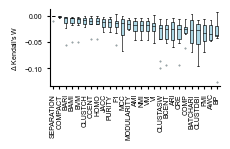

In [33]:
order = merged.groupby("Metric")["diff_W"].median().sort_values(ascending=False).index

boxplot_data = [merged[merged["Metric"] == metric]["diff_W"].values for metric in order]

# 3. Create the boxplot using subplots
fig, ax = plt.subplots(figsize=(2.4, 1.6))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# 4. Customize labels and layout
ax.set_ylabel("$\\Delta$ Kendall's W", fontsize=5)
# ax.set_xlabel("Metric", fontsize=5)
# ax.set_title("Distribution of Kendall's W across Datasets by Metric")
plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/clustering_louvain_neighbor_k_W.svg', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
merged.groupby("Metric")["diff_W"].mean().sort_values()

Metric
BP           -0.037843
CLUSTDBI     -0.037677
CLUSTASW     -0.037627
CRE          -0.034708
BCENT        -0.034691
FMI          -0.033727
AWC          -0.030560
BATCHARI     -0.030410
ARI          -0.028522
COMP         -0.028486
MCC          -0.024555
VI           -0.022942
NMI          -0.021300
VM           -0.021300
AMI          -0.021258
F1           -0.018695
MODULARITY   -0.015636
JACC         -0.013757
PURITY       -0.013757
BARI         -0.013377
HOMO         -0.013214
CCENT        -0.013172
BVM          -0.012973
BAMI         -0.012934
CLUSTCH      -0.009551
SEPARATION   -0.001809
COMPACT      -0.001657
Name: diff_W, dtype: float64

In [35]:
merged.groupby("Metric")["prop_W"].mean().sort_values()

Metric
CLUSTASW      0.960400
CLUSTDBI      0.961339
BP            0.961345
CRE           0.964079
BCENT         0.964096
FMI           0.964828
AWC           0.968197
BATCHARI      0.968813
ARI           0.970319
COMP          0.970819
MCC           0.974895
VI            0.976294
NMI           0.978027
VM            0.978027
AMI           0.978069
F1            0.980826
MODULARITY    0.984294
JACC          0.985906
PURITY        0.985906
BARI          0.986272
HOMO          0.986647
CCENT         0.986690
BVM           0.986744
BAMI          0.986783
CLUSTCH       0.990409
SEPARATION    0.998190
COMPACT       0.998342
Name: prop_W, dtype: float64

In [36]:
df_wide = merged.pivot_table(index='Dataset', columns='Metric', values="diff_W", aggfunc='mean')
pairs = [
    ('BARI', 'ARI'),
    ('BAMI', 'AMI'),
    ('BVM', 'VM')
]

l = []
for m1, m2 in pairs:
    l.append(df_wide[[m1, m2]].to_numpy())
l = np.concatenate(l)
wilcoxon(l[:, 0], l[:, 1])

WilcoxonResult(statistic=np.float64(35.0), pvalue=np.float64(0.0010160311224942627))

In [37]:
df_wide = merged.pivot_table(index='Dataset', columns='Metric', values="diff_W", aggfunc='mean')
pairs = [
    ('AMI', 'ARI'),
    ('BAMI', 'BARI')
]

l = []
for m1, m2 in pairs:
    l.append(df_wide[[m1, m2]].to_numpy())
l = np.concatenate(l)
wilcoxon(l[:, 0], l[:, 1])

WilcoxonResult(statistic=np.float64(37.0), pvalue=np.float64(0.116668701171875))

## Differences in coefficient of variation

In [38]:
df_full = pd.concat([df_1, df_2, df_3, df_4, df_5, df_6, df_7, df_8])
df_full = df_full[df_full.Metric != 'ISOF1']
df_full.replace([np.inf, -np.inf], np.nan, inplace=True)

In [39]:
cvs = df_full.pivot(index=['Dataset', 'Integration', 'neighbor_k'],
                    columns='Metric', values="Value").groupby(['Dataset', 'neighbor_k'])[df_full.Metric.unique()].apply(
    lambda x: x.std() / x.mean().abs()
).reset_index()

In [40]:
def plot_cv_metrics(
    df: pd.DataFrame,
    dataset_col: str = "Dataset",
    k_col: str = "neighbor_k",
    reference_k: int = 15,
    ncols: int = 6,
    figsize_per_cell: tuple = (1.1, 1),
    alpha_levels: tuple = (0.05, 0.01, 0.001),
    color: str = "#378ADD",
    adjustment_method: str = "fdr_bh",
):
    """
    Plot small-multiple line charts of coefficient of variation (CV) vs neighbor_k,
    averaged across datasets, with Wilcoxon signed-rank significance stars
    compared to a reference k value.
 
    Parameters
    ----------
    df : pd.DataFrame
        Must contain `dataset_col`, `k_col`, and one column per metric.
    dataset_col : str
        Column name identifying datasets.
    k_col : str
        Column name for neighbor_k values.
    reference_k : int
        The k value to test significance against (default 15).
    ncols : int
        Number of columns in the small-multiple grid.
    figsize_per_cell : tuple
        (width, height) in inches for each subplot cell.
    alpha_levels : tuple
        Thresholds for *, **, *** significance (default 0.05, 0.01, 0.001).
    color : str
        Line/marker color.
    """
    import matplotlib.ticker as mticker
    from scipy.stats import wilcoxon
    metric_cols = ordered_metrics
    k_values = sorted(df[k_col].unique())
    n_metrics = len(metric_cols)
    nrows = math.ceil(n_metrics / ncols)
 
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_cell[0] * ncols, figsize_per_cell[1] * nrows),
        constrained_layout=True,
    )
    axes_flat = np.array(axes).flatten()
 
    ref_data = {}
    for metric in metric_cols:
        ref_subset = df[df[k_col] == reference_k][metric].dropna().values
        ref_data[metric] = ref_subset
        
    raw_p_values = {}
    means_per_metric = {}
    stderrs_per_metric = {}
 
    for metric in metric_cols:
        means, stderrs = [], []
        for k in k_values:
            vals = df[df[k_col] == k][metric].dropna().values
            means.append(np.mean(vals))
            stderrs.append(np.std(vals, ddof=1) / np.sqrt(len(vals)))
 
            if k != reference_k and len(vals) >= 2 and len(ref_data[metric]) >= 2:
                ref_vals = ref_data[metric]
                min_len = min(len(vals), len(ref_vals))
                diffs = vals[:min_len] - ref_vals[:min_len]
                if np.any(diffs != 0):
                    _, p = wilcoxon(diffs)
                else:
                    p = 1.0
                raw_p_values[(metric, k)] = p
 
        means_per_metric[metric] = np.array(means)
        stderrs_per_metric[metric] = np.array(stderrs)
        
    keys = list(raw_p_values.keys())
    raw_p_array = np.array([raw_p_values[k] for k in keys])
    _, adj_p_array, _, _ = multipletests(raw_p_array, method=adjustment_method)
    adj_p_values = dict(zip(keys, adj_p_array))
 
    for idx, metric in enumerate(metric_cols):
        ax = axes_flat[idx]
        means = means_per_metric[metric]
        stderrs = stderrs_per_metric[metric]
 
        ax.plot(k_values, means, color=color, linewidth=.45, zorder=3,
                marker="o", markersize=2, markerfacecolor="white",
                markeredgecolor=color, markeredgewidth=.45)

 
        ax.axvline(reference_k, color="#888780", linewidth=1,
                   linestyle="--", zorder=1, alpha=0.7)
 
        y_range = ax.get_ylim()[1] - ax.get_ylim()[0]
        point_offset = y_range * 0.04
        
        point_offset = y_range * 0.04
        for i, k in enumerate(k_values):
            if k == reference_k or (metric, k) not in adj_p_values:
                continue
            p = adj_p_values[(metric, k)]
            if p < alpha_levels[2]:
                stars = "***"
            elif p < alpha_levels[1]:
                stars = "**"
            elif p < alpha_levels[0]:
                stars = "*"
            else:
                stars = "ns"
 
            if stars != "ns":
                point_y = means[k_values.index(k)]
                ax.text(k, point_y + point_offset, stars, ha="center", va="bottom",
                        fontsize=9, color="#D85A30", fontweight="bold",
                        clip_on=False)
 
        ax.set_title(metric, fontsize=5, fontweight="medium", pad=6)
        last_row_start = (nrows - 1) * ncols
        is_bottom = last_row_start <= idx < last_row_start + ncols and idx < n_metrics
        is_left = idx % ncols == 0
        if is_bottom:
            ax.set_xlabel("k", fontsize=5)
        if is_left:
            ax.set_ylabel("CV", fontsize=5)
        ax.set_xticks(k_values)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        ax.set_xlim(3, 27)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(0.45)
        ax.spines["bottom"].set_linewidth(0.45)
#         ticks = ax.yaxis.get_majorticklocs()
#         fmt = "%.2f" if all(round(t, 2) == round(t, 3) for t in ticks) else "%.3f"
#         ax.yaxis.set_major_formatter(mticker.FormatStrFormatter(fmt))
 
    for idx in range(n_metrics, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    return fig

/tmp/ipykernel_3304871/2904256784.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


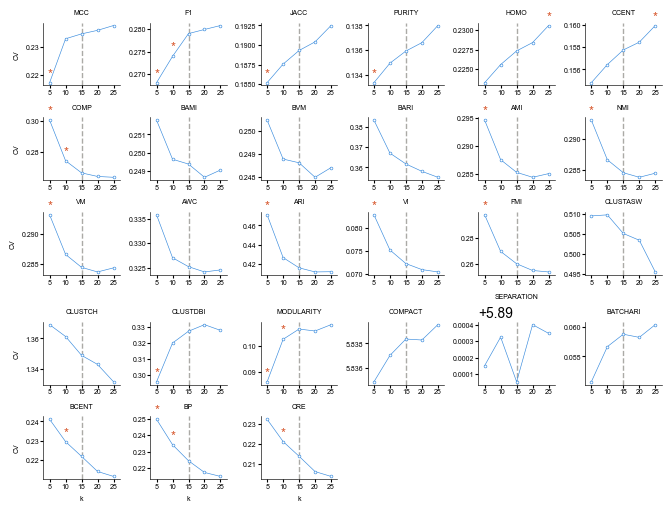

In [41]:
fig = plot_cv_metrics(cvs)
# fig.savefig('../publication_figures/louvain_clustering_neighbor_k_cvs.png', dpi=300, bbox_inches='tight')
fig.show()